# Temporal Convolutional Attention Networks for U.S. Energy Forecasting

## 1. Project Environment and Output Configuration

In [ ]:
from pathlib import Path
import os, math, random, json, warnings, sys, hashlib
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from scipy.stats import norm, t as student_t
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import GradientBoostingRegressor
from IPython.display import display, Image


def find_project_root():
    locations=[]
    here=Path.cwd().resolve()
    locations.extend([here, *here.parents, Path('/content'), Path('/mnt/data')])
    explicit=os.getenv('TCANN_PROJECT_ROOT')
    if explicit:locations.insert(0,Path(explicit))
    for p in locations:
        if (p/'RESULTS'/'US_Energy_Dataset.csv').is_file():return p
        if p.exists():
            for child in p.glob('*/RESULTS/US_Energy_Dataset.csv'):
                return child.parent.parent
    raise FileNotFoundError('Extract the project ZIP, then use the project directory containing RESULTS/US_Energy_Dataset.csv.')

ROOT=find_project_root()
OUT=ROOT/'RESULTS';OUT.mkdir(parents=True,exist_ok=True)
DATA_FILE=OUT/'US_Energy_Dataset.csv'
SMOKE = os.environ.get('TCANN_SMOKE','0') == '1'
SUFFIX='_SMOKE' if SMOKE else '_Recomputed'
WINDOW=24  
EPOCHS=1 if SMOKE else 100
BATCH_SIZE=32
SEEDS=[7,21,42,123,2025]
MAIN_SEED=42
RUN_SMOKE_EXTRAS=os.getenv('TCANN_SMOKE_EXTRAS','0')=='1'
RUN_ROBUSTNESS=not SMOKE
RUN_CLASSICAL=(not SMOKE) or RUN_SMOKE_EXTRAS
RUN_ABLATIONS=(not SMOKE) or RUN_SMOKE_EXTRAS
RUN_HYPERPARAMS=(not SMOKE) or RUN_SMOKE_EXTRAS
RUN_BACKTEST=(not SMOKE) or RUN_SMOKE_EXTRAS
SARIMA_MAX_CANDIDATES=2 if SMOKE else None  # None = full 144-combination search in the paper's parameter ranges.
NAMES=['TFFP','NEPP','TREP','TPEP','PEI','PEE','TFFC','NEPC','TREC','TPEC']
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def fix_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
fix_seed(MAIN_SEED)

def path_result(stem,ext='csv'):
    return OUT/f'{stem}{SUFFIX}.{ext}'

def save_table(data,stem):
    p=path_result(stem)
    frame=pd.DataFrame(data)
    frame.to_csv(p,index=False)
    print('Output:',p.resolve())
    with pd.option_context('display.max_rows',100,'display.max_columns',40,'display.width',180):
        display(frame)
    return frame

def save_plot(fig,number):
    p=path_result(f'Figure_{number:02d}','png')
    fig.savefig(p,dpi=170,bbox_inches='tight',facecolor='white')
    plt.close(fig)
    print('Output:',p.resolve())
    display(Image(filename=str(p)))
    return p

print('Project:', ROOT.resolve())
print('Dataset:',DATA_FILE.resolve())
print('Outputs:',OUT.resolve())
print('Runtime:',torch.__version__,'device:',DEVICE,'mode:','SMOKE TEST' if SMOKE else '100-EPOCH EXPERIMENT')


## 2. Dataset Loading and Validation

In [ ]:
raw=pd.read_csv(DATA_FILE)
assert raw.shape==(628,11),f'Expected 628 observations / 10 variables: {raw.shape}'
raw['Month']=pd.to_datetime(raw['Month'],format='%Y %B',errors='raise')
raw=raw.sort_values('Month').drop_duplicates('Month').reset_index(drop=True)
assert len(raw)==628
assert raw.Month.tolist()==list(pd.date_range('1973-01-01','2025-04-01',freq='MS'))
raw.columns=['Month']+NAMES
for col in NAMES:raw[col]=pd.to_numeric(raw[col],errors='coerce')
n_train,n_val,n_test=439,94,95
assert (n_train,n_val,n_test)==(439,94,95)
assert raw.Month.iloc[438]==pd.Timestamp('2009-07-01')
assert raw.Month.iloc[532]==pd.Timestamp('2017-05-01')
assert raw.Month.iloc[533]==pd.Timestamp('2017-06-01')

table3=raw.iloc[[0,1,2,-1]].copy()
table3['Month']=table3['Month'].dt.strftime('%B %Y')
save_table(table3.round(6),'Table_03')
save_table(pd.DataFrame({'Series':NAMES,
  'Missing':[int(raw[v].isna().sum()) for v in NAMES],
  'Min_QBTU':[raw[v].min() for v in NAMES],
  'Max_QBTU':[raw[v].max() for v in NAMES]}),'Data_Quality')


In [ ]:
output_path = OUT / "Table_03_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Month,TFFP,NEPP,TREP,TPEP,PEI,PEE,TFFC,NEPC,TREC,TPEC
January 1973,4.9326,0.0681,0.2198,5.2206,1.1731,0.1258,6.7477,0.0681,0.2198,7.0397
February 1973,4.7296,0.0646,0.1973,4.9915,1.1680,0.1209,6.1631,0.0646,0.1973,6.4288
March 1973,4.9469,0.0725,0.2187,5.2381,1.3095,0.1400,6.0446,0.0725,0.2187,6.3400
.,.,.,.,.,.,.,.,.,.,.
.,.,.,.,.,.,.,.,.,.,.
April 2025,7.3242,0.6051,0.7721,8.7014,1.6282,2.5301,5.9259,0.6051,0.7534,7.2889


## 3. Data Visualization and Monthly Patterns

In [ ]:
pairs=[('TFFP','TFFC'),('TPEP','TPEC'),('TREP','TREC'),('NEPP','NEPC'),('PEI','PEE')]
fig,axs=plt.subplots(3,2,figsize=(12,10),sharex=True)
for ax,(a,b) in zip(axs.ravel(),pairs):
    ax.plot(raw.Month,raw[a].rolling(12).mean(),label=a,lw=1.6)
    ax.plot(raw.Month,raw[b].rolling(12).mean(),label=b,lw=1.6)
    ax.legend();ax.set_ylabel('QBTU');ax.grid(alpha=.18)
axs.ravel()[-1].axis('off');fig.tight_layout();save_plot(fig,2)


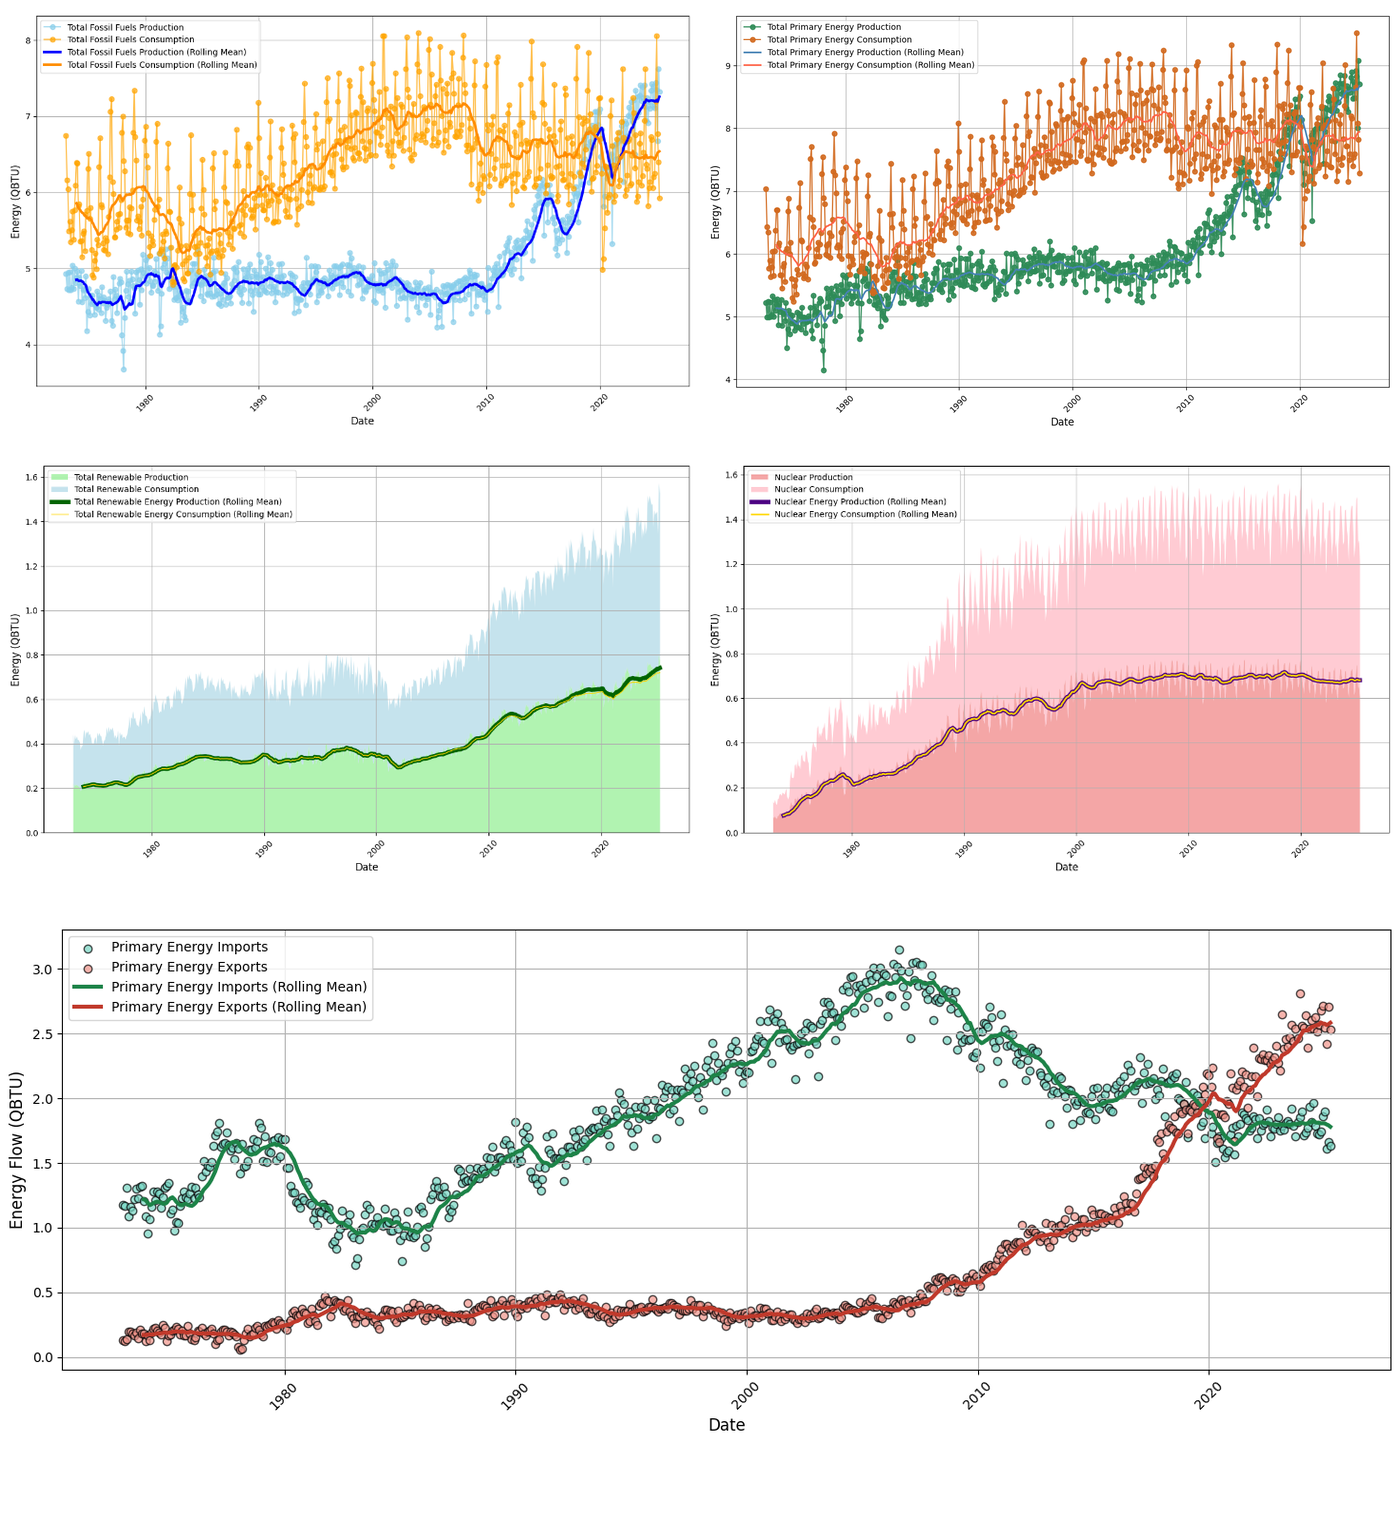

In [ ]:
output_path = OUT / "Figure_02_Paper_Original.png"
display(Image(filename=str(output_path)))

## 4. Chronological Splitting, Preprocessing and Accounting

In [ ]:
train=raw[NAMES].iloc[:n_train]
train_clean=train.interpolate(method='linear',limit_direction='both').ffill().bfill()
actual_clean=raw[NAMES].copy()
actual_clean.iloc[:n_train]=train_clean
actual_clean=actual_clean.ffill()
if actual_clean.isna().any().any():
    raise ValueError('Missing values remain after chronological interpolation and forward fill.')
q1=train_clean.quantile(.25);q3=train_clean.quantile(.75)
lower=q1-1.5*(q3-q1);upper=q3+1.5*(q3-q1)

input_clean=actual_clean.clip(lower=lower,upper=upper,axis='columns')
scale_min=input_clean.iloc[:n_train].min().to_numpy(dtype='float32')
scale_span=(input_clean.iloc[:n_train].max()-input_clean.iloc[:n_train].min()).to_numpy(dtype='float32')
scale_span=np.maximum(scale_span,1e-8)
x_scaled=((input_clean.to_numpy(dtype='float32')-scale_min)/scale_span).astype('float32')
y_actual=actual_clean.to_numpy(dtype='float32')
y_scaled=((y_actual-scale_min)/scale_span).astype('float32')

def inverse_transform(a):
    return np.asarray(a,dtype='float64')*scale_span+scale_min

def supervised(start,end):
    xx=np.stack([x_scaled[t-WINDOW:t] for t in range(start,end)])
    yy=y_scaled[start:end]
    return xx.astype('float32'),yy.astype('float32')

Xtr,Ytr=supervised(WINDOW,n_train)
Xva,Yva=supervised(n_train,n_train+n_val)
Xte,Yte=supervised(n_train+n_val,len(raw))
Xtr_fit,Ytr_fit=(Xtr[:64],Ytr[:64]) if SMOKE else (Xtr,Ytr)
assert Xtr.shape==(415,24,10) and Xva.shape==(94,24,10) and Xte.shape==(95,24,10)
assert np.allclose(inverse_transform(Yte),y_actual[533:],atol=2e-6)


NET_IMPORT_FILE=OUT/'Electricity_Net_Imports_QBTU.csv'
observed_net_imports=None
if NET_IMPORT_FILE.exists():
    imports=pd.read_csv(NET_IMPORT_FILE)
    required={'Month','Electricity_Net_Imports_QBTU'}
    if not required.issubset(imports.columns):
        raise ValueError(f'{NET_IMPORT_FILE.name} must have columns {required}')
    imports['Month']=pd.to_datetime(imports['Month'])
    if imports['Month'].duplicated().any():
        raise ValueError('Electricity net-import series contains duplicate months.')
    observed_net_imports=imports.set_index('Month')['Electricity_Net_Imports_QBTU']

ACCOUNTING_TOL_QBTU=0.001

def accounting(frame,period):
    production_diff=(frame['TPEP']-frame['TFFP']-frame['NEPP']-frame['TREP']).to_numpy(dtype='float64')
    implied_net_import=(frame['TPEC']-frame['TFFC']-frame['NEPC']-frame['TREC']).to_numpy(dtype='float64')
    if observed_net_imports is None:
        observed=np.full(len(frame),np.nan)
    else:
        observed=frame['Month'].map(observed_net_imports).to_numpy(dtype='float64')
    consumption_diff=implied_net_import-observed
    prod_pass=np.abs(production_diff)<=ACCOUNTING_TOL_QBTU
    cons_verified=np.isfinite(consumption_diff)
    return pd.DataFrame({
        'Month':frame['Month'], 'Period':period,
        'Production_difference_QBTU':production_diff,
        'Production_identity_pass':prod_pass,
        'Implied_electricity_net_imports_QBTU':implied_net_import,
        'Observed_electricity_net_imports_QBTU':observed,
        'Consumption_identity_difference_QBTU':consumption_diff,
        'Consumption_identity_verifiable':cons_verified,
        'Consumption_identity_pass':np.where(cons_verified,np.abs(consumption_diff)<=ACCOUNTING_TOL_QBTU,np.nan)
    })

historical_accounts=accounting(raw,'Historical')
save_table(historical_accounts,'Energy_Accounting_Historical')
save_table(pd.DataFrame({'Variable':NAMES,'Training_Min':scale_min,'Training_Span':scale_span,
 'IQR_Lower':lower.to_numpy(),'IQR_Upper':upper.to_numpy()}),'Preprocessing_Parameters')
print('Historical production identity within tolerance:', int(historical_accounts.Production_identity_pass.sum()),'/',len(raw))
print('Historical max absolute production residual:',float(historical_accounts.Production_difference_QBTU.abs().max()),'QBTU')
print('Historical consumption identity independently verifiable:',bool(historical_accounts.Consumption_identity_verifiable.all()))


## 5. TCANN and Benchmark Model Architectures

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

N_FEATURES = 10


def entmax15(x, dim=-1, steps=40):
    """Differentiable alpha-entmax with alpha=1.5, using a scalar threshold root.
    Input is centered to avoid overflow and p_i=max((x_i/2-tau),0)^2.
    """
    x = (x - x.max(dim=dim, keepdim=True).values) / 2.0
    lo = x.min(dim=dim, keepdim=True).values - 1.0
    hi = x.max(dim=dim, keepdim=True).values
    for _ in range(steps):
        mid = (lo + hi) / 2
        z = F.relu(x - mid).square().sum(dim=dim, keepdim=True)
        lo = torch.where(z > 1, mid, lo)
        hi = torch.where(z > 1, hi, mid)
    p = F.relu(x - (lo + hi) / 2).square()
    return p / p.sum(dim=dim, keepdim=True).clamp_min(1e-12)


class CausalConv(nn.Module):
    def __init__(self, din, dout, kernel, dilation, dropout):
        super().__init__()
        self.left = (kernel-1)*dilation
        self.conv = nn.Conv1d(din, dout, kernel, dilation=dilation)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(F.relu(self.conv(F.pad(x, (self.left, 0)))))


class GaussianHead(nn.Module):
    def __init__(self, hidden, targets=10):
        super().__init__()
        self.out = nn.Linear(hidden, 2*targets)
    def forward(self, x):
        return self.out(x)


class TCANN(nn.Module):
    def __init__(self, window=24, channels=64, dropout=0.20,
                 ablation=None, depth=5):
        super().__init__()
        self.ablation = ablation
        self.input_proj = nn.Linear(N_FEATURES, channels) if ablation == 'no_convolution' else None
        if self.input_proj is None:
            self.convs = nn.ModuleList()
            din=N_FEATURES
            for d in (1,2,4,8,16)[:depth]:
                self.convs.append(CausalConv(din,channels,3,d,dropout))
                din=channels
        self.att_proj = nn.Linear(channels,64)
        self.att_score = nn.Linear(64,1)
        self.fuse = nn.Sequential(nn.Linear(128 if ablation!='no_attention' else 64,64),nn.ReLU())
        self.head = GaussianHead(64)
        self.last_attention=None
    def forward(self, x):
        if self.input_proj is not None:
            z=F.relu(self.input_proj(x))
        else:
            z=x.transpose(1,2)
            for conv in self.convs: z=conv(z)
            z=z.transpose(1,2)
        last=z[:,-1,:]
        if self.ablation!='no_attention':
            logits=self.att_score(torch.tanh(self.att_proj(z))).squeeze(-1)
            att=entmax15(logits,dim=-1)
            self.last_attention=att
            context=(z*att.unsqueeze(-1)).sum(dim=1)
            last=torch.cat([last,context],dim=-1)
        else:
            self.last_attention=None
        return self.head(self.fuse(last))


class RecurrentForecaster(nn.Module):
    def __init__(self, kind='LSTM', dropout=0.20):
        super().__init__()
        rnn=nn.GRU if kind=='GRU' else nn.LSTM
        self.rnn=rnn(N_FEATURES,64,num_layers=2,dropout=dropout,batch_first=True)
        self.head = GaussianHead(64) if kind=='DeepAR' else nn.Linear(64,N_FEATURES)
    def forward(self,x):
        y,_=self.rnn(x)
        return self.head(y[:,-1,:])


class GraphGRUCell(nn.Module):
    """Node-wise recurrent cell with learned cross-node diffusion and memory readout."""
    def __init__(self, hidden=64, memory_dim=32, input_dim=1):
        super().__init__()
        self.gates=nn.Linear(input_dim+hidden+hidden+memory_dim,2*hidden)
        self.candidate=nn.Linear(input_dim+hidden+hidden+memory_dim,hidden)
    def forward(self,x,h,adj,memory):
        neighbors=torch.einsum('ij,bjh->bih',adj,h)
        z=torch.cat([x,h,neighbors,memory],dim=-1)
        r,u=torch.sigmoid(self.gates(z)).chunk(2,dim=-1)
        cand=torch.tanh(self.candidate(torch.cat([x,r*h,neighbors,memory],dim=-1)))
        return (1-u)*h+u*cand


class MegaCRN(nn.Module):
    """Documented memory-augmented adaptive graph recurrent adaptation for 10 series."""
    def __init__(self, hidden=64, nodes=10, slots=20, memory_dim=32):
        super().__init__()
        self.nodes=nodes;self.hidden=hidden
        self.node_embeddings=nn.Parameter(torch.randn(nodes,memory_dim)*0.05)
        self.memory_bank=nn.Parameter(torch.randn(slots,memory_dim)*0.05)
        self.query=nn.Linear(hidden,memory_dim)
        self.cell1=GraphGRUCell(hidden,memory_dim)
        self.cell2=GraphGRUCell(hidden,memory_dim,input_dim=hidden)
        self.node_head=nn.Linear(hidden,1)
    def forward(self,x):
        batch,time,n=x.shape
        if n!=self.nodes:raise ValueError('Graph expects 10 energy variables.')
        adj=F.softmax(F.relu(self.node_embeddings @ self.node_embeddings.T),dim=-1)
        h1=x.new_zeros(batch,self.nodes,self.hidden)
        h2=x.new_zeros(batch,self.nodes,self.hidden)
        for t in range(time):
            q=self.query(h2)+self.node_embeddings.unsqueeze(0)
            alpha=F.softmax(q @ self.memory_bank.T,dim=-1)
            mem=alpha @ self.memory_bank
            h1=self.cell1(x[:,t,:].unsqueeze(-1),h1,adj,mem)
            h2=self.cell2(h1,h2,adj,mem)
        return self.node_head(h2).squeeze(-1)


def transformer_layer(d_model=64, nhead=4):
    return nn.TransformerEncoderLayer(d_model=d_model,nhead=nhead,
                        dim_feedforward=256,dropout=0.10,activation='gelu',batch_first=True,norm_first=False)


class PatchTST(nn.Module):
    """Channel-independent patch-token forecasting (24 months -> 4 non-overlapping patches)."""
    def __init__(self,window=24,patch=6,d_model=64,n_heads=4,n_layers=2):
        super().__init__()
        assert window%patch==0
        self.window=window;self.patch=patch
        self.npatch=window//patch
        self.embed=nn.Linear(patch,d_model)
        self.pos=nn.Parameter(torch.zeros(1,self.npatch,d_model))
        self.encoder=nn.TransformerEncoder(transformer_layer(d_model,n_heads),num_layers=n_layers,enable_nested_tensor=False)
        self.head=nn.Linear(self.npatch*d_model,1)
    def forward(self,x):
        b,l,c=x.shape
        patches=x.transpose(1,2).reshape(b*c,self.npatch,self.patch)
        tokens=self.encoder(self.embed(patches)+self.pos)
        return self.head(tokens.flatten(1)).reshape(b,c)


class TimesBlock(nn.Module):
    """FFT-selected top-k periods with 2-D temporal mixing and residual block."""
    def __init__(self,dim=64,k=5):
        super().__init__()
        self.k=k
        self.conv=nn.Sequential(nn.Conv2d(dim,dim,3,padding=1),nn.GELU(),
                                 nn.Conv2d(dim,dim,3,padding=1),nn.GELU())
        self.norm=nn.LayerNorm(dim)
    def forward(self,x):
        b,t,d=x.shape
        xf=torch.fft.rfft(x.float(),dim=1)
        amps=xf.abs().mean(dim=(0,2))
        amps=amps.clone()
        amps[0]=0.0
        inds=torch.topk(amps,k=min(self.k,max(1,len(amps)-1))).indices
        if len(inds)==0:return x
        weights=F.softmax(amps[inds],dim=0)
        branches=[]
        for idx in inds.tolist():
            period=max(1,int(round(t/idx)))
            padding=(-t)%period
            z=F.pad(x,(0,0,0,padding)) if padding else x
            length=z.shape[1]
            z=z.reshape(b,length//period,period,d).permute(0,3,1,2)
            z=self.conv(z).permute(0,2,3,1).reshape(b,length,d)[:,:t,:]
            branches.append(z)
        mixed=sum(w*v for w,v in zip(weights,branches))
        return self.norm(x+mixed)


class TimesNet(nn.Module):
    def __init__(self,window=24,dim=64,n_blocks=2,top_k=5):
        super().__init__()
        self.embed=nn.Linear(N_FEATURES,dim)
        self.blocks=nn.ModuleList([TimesBlock(dim,top_k) for _ in range(n_blocks)])
        self.head=nn.Linear(window*dim,N_FEATURES)
    def forward(self,x):
        h=self.embed(x)
        for blk in self.blocks:h=blk(h)
        return self.head(h.flatten(1))


class iTransformer(nn.Module):
    """Variate-as-token inverted transformer, dim64, 4 heads, 2 encoders."""
    def __init__(self,window=24,dim=64,heads=4,layers=2):
        super().__init__()
        self.embedding=nn.Linear(window,dim)
        self.encoder=nn.TransformerEncoder(transformer_layer(dim,heads),num_layers=layers,enable_nested_tensor=False)
        self.head=nn.Linear(dim,1)
    def forward(self,x):
        variates=x.transpose(1,2)
        tokens=self.encoder(self.embedding(variates))
        return self.head(tokens).squeeze(-1)


class TCN(nn.Module):
    def __init__(self,filters=64,depth=3,window=24):
        super().__init__()
        blocks=[];din=N_FEATURES
        for dilation in (1,2,4,8,16)[:depth]:
            blocks.append(CausalConv(din,filters,2,dilation,0.10));din=filters
        self.net=nn.Sequential(*blocks)
        self.head=nn.Linear(filters,N_FEATURES)
    def forward(self,x):
        return self.head(self.net(x.transpose(1,2))[:,:,-1])


PROB_MODELS=('TCANN','DeepAR')
MODEL_NAMES=('TCANN','LSTM','GRU','MegaCRN','DeepAR','PatchTST','TimesNet','iTransformer')

def make_model(name,window=24,**kwargs):
    if name=='TCANN':return TCANN(window=window,**kwargs)
    if name in ('LSTM','GRU','DeepAR'):return RecurrentForecaster(name)
    if name=='MegaCRN':return MegaCRN()
    if name=='PatchTST':return PatchTST(window=window)
    if name=='TimesNet':return TimesNet(window=window)
    if name=='iTransformer':return iTransformer(window=window)
    if name=='TCN':return TCN(window=window,**kwargs)
    raise ValueError(f'Unknown model: {name}')


def gaussian_nll(target,raw,n_features=10):
    mean=raw[...,:n_features]
    variance=F.softplus(raw[...,n_features:])+1e-6
    return (0.5*(torch.log(2*math.pi*variance)+(target-mean).square()/variance)).mean()


def mean_variance(raw,probabilistic,features=10):
    if not probabilistic:return raw,None
    return raw[:,:features],F.softplus(raw[:,features:])+1e-6


def model_self_test():
    assert set(MODEL_NAMES)==set(['TCANN','LSTM','GRU','MegaCRN','DeepAR','PatchTST','TimesNet','iTransformer'])
    x=torch.randn(2,24,10)
    y=torch.randn(2,10)
    for name in (*MODEL_NAMES,'TCN'):
        m=make_model(name)
        z=m(x)
        assert z.shape==(2,20 if name in PROB_MODELS else 10), (name,z.shape)
        loss=gaussian_nll(y,z) if name in PROB_MODELS else F.mse_loss(z,y)
        assert torch.isfinite(loss),name
        loss.backward()
        assert any(p.grad is not None and torch.isfinite(p.grad).all() for p in m.parameters()),name
        print('OK',name,'forward/backward',round(float(loss),4))
    for var in ('no_attention','no_convolution'):
        m=make_model('TCANN',ablation=var)
        z=m(x);gaussian_nll(y,z).backward()
        print('OK',var)
    probs=entmax15(torch.randn(6,17))
    assert torch.allclose(probs.sum(-1),torch.ones(6),atol=1e-4)
    assert (probs>=0).all()



In [ ]:
# Study workflow and exact on-disk figure path.
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(14,3.5));ax.set_xlim(0,14);ax.set_ylim(0,4);ax.axis('off')
steps=['1973–2025\nmonthly data','439 / 94 / 95\nsplit','Train-only\nscaling + IQR','14 forecasting\narchitectures','Rolling-origin\nevaluation','2035 recursive\nscenario']
for i,label in enumerate(steps):
    x=0.15+i*2.3
    ax.text(x+1.0,2,label,ha='center',va='center',fontsize=9.5,
      bbox={'boxstyle':'round,pad=.6','fc':'#e9f3fb','ec':'#355f7c'})
    if i<5:ax.annotate('',xy=(x+2.13,2),xytext=(x+1.8,2),arrowprops={'arrowstyle':'->','lw':1.5})
fig.tight_layout();save_plot(fig,1)


config4=[
 ('Dataset','U.S. monthly data Jan 1973 to Apr 2025'),
 ('Data split','439 train, 94 validation, 95 test; chronological'),
 ('TCANN input window','24 months: implementation assumption, not fixed in paper'),
 ('Causal convolutions','5 layers, 64 filters, kernel=3, dilations=1,2,4,8,16'),
 ('Regularization','Dropout 0.20; ReLU'),
 ('Attention','Single-head temporal alpha-entmax, alpha=1.5, dim=64'),
 ('Gaussian output','10 means + 10 positive variances; Gaussian NLL'),
 ('Optimizer','Adam, fixed LR=0.001, no early stopping'),
 ('Training','100 epochs, batch size 32'),
 ('Metrics','MSE QBTU2, RMSE/MAE QBTU, MAPE %, Gaussian NLL, PICP, MPIW'),
 ('Forecasting','One-step test evaluation; recursive 2025-05 to 2035-12')]
save_table(pd.DataFrame(config4,columns=['Parameter','Configuration']),'Table_04')
model_configs=[
 ('TCANN','5 causal conv, filters64, k3, d=1/2/4/8/16, dropout.20; alpha-entmax1.5, Gaussian NLL', '24-month window chosen'),
 ('LSTM','2 layers, 64 hidden units, dropout.20, LR.001','Matched specified architecture'),
 ('GRU','2 layers, 64 hidden units, dropout.20, LR.001','Matched specified architecture'),
 ('MegaCRN','10-node adaptive graph, hidden64, memory20x32, LR.001','Research adaptation; not exact official MegaCRN code'),
 ('DeepAR','2 recurrent layers, hidden64, Gaussian likelihood, LR.001','Next-step conditional Gaussian multi-target adaptation'),
 ('PatchTST','Input24, patch6, 4 heads, 2 encoder layers','Channel-independent patches'),
 ('TimesNet','Input24, model dim64, 2 TimesBlocks, top-k5','FFT-selected 2D temporal periods'),
 ('iTransformer','Input24, dim64, 4 heads, 2 encoder layers','Variates used as attention tokens'),
 ('Persistence','Observed previous month','Fixed'),
 ('Seasonal-Naive','Observed value at t−12','Fixed'),
 ('SARIMA','(p,d,q)(P,D,Q)12, p,q 0-2; d,P,D,Q 0-1','144-candidate validation search'),
 ('ETS','Additive trend, damping, additive 12-month seasonal','Rolling-origin refit'),
 ('Gradient Boosting','lags 1,2,3,6,12,24; estimators 100/300/500; depth2/3/5; LR.03/.1','54-candidate validation search'),
 ('TCN','3 or 5 causal conv layers; 32 or 64 filters; kernel2; dropout.10; LR.001','4-candidate validation search')]
save_table(pd.DataFrame(model_configs,columns=['Model','Manuscript_configuration','Implementation_note']),'Table_05')

fig,ax=plt.subplots(figsize=(13,3.4));ax.set_xlim(0,13);ax.set_ylim(0,4);ax.axis('off')
blocks=[('Input 24×10',.2),('5 causal conv\n64 filters, d=1…16',2.7),
        ('Temporal α-entmax\nα=1.5, dim64',5.4),('Context + last\nhidden state',8.1),
        ('Gaussian head\n10 means + variances',10.7)]
for i,(label,x) in enumerate(blocks):
    ax.text(x+1,2,label,ha='center',va='center',fontsize=10,
            bbox=dict(boxstyle='round,pad=.6',fc='#ecf6ed',ec='#40734d'))
    if i<len(blocks)-1:ax.annotate('',(x+2.45,2),(x+2,2),arrowprops=dict(arrowstyle='->'))
fig.tight_layout();save_plot(fig,3)


In [ ]:
output_path = OUT / "Table_04_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Component,Description/Value
Dataset,"U.S. monthly energy production, consumption and trade data (January 1973-April 2025)"
Data Preprocessing,Linear interpolation for missing values; IQR-based outlier handling using training-derived thresholds; Min-Max normalization fitted on the training partition
Data Split,Chronological 70:15:15 split: Training = Jan 1973-Jul 2009 (439 observations); Validation = Aug 2009-May 2017 (94 observations); Testing = Jun 2017-Apr 2025 (95 observations); no random shuffling
Model Architecture,TCANN
Temporal Convolution Layers,5 causal dilated convolutional layers
Filters,64 filters per convolutional layer
Kernel Size,3
Dilation Factors,"1, 2, 4, 8, 16"
Activation Function,ReLU
Regularization,Dropout = 0.20


In [ ]:
output_path = OUT / "Table_05_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Model,Configuration
TCANN,"5 causal dilated convolution layers, 64 filters, kernel size 3, dilations (1, 2, 4, 8, 16), dropout 0.20, α-entmax (α = 1.5), attention dimension 64, Gaussian output, Adam, LR 0.001"
LSTM,"2 layers, 64 hidden units, dropout 0.20, LR 0.001"
GRU,"2 layers, 64 hidden units, dropout 0.20, LR 0.001"
MegaCRN,10 energy variables as graph nodes; adaptive graph learning; 64 hidden units; 20 memory slots; memory dimension 32; learning rate 0.001
DeepAR,"2 recurrent layers, 64 hidden units, Gaussian likelihood, LR 0.001"
PatchTST,"Input window 24 months, patch length 6, 4 attention heads, 2 encoder layers"
TimesNet,"Input window 24 months, model dimension 64, 2 blocks, top-k 5"
iTransformer,"Input window 24 months, model dimension 64, 4 attention heads, 2 encoder layers"
Persistence,Previous month's observed value; no hyperparameter tuning
Seasonal-Naïve,Corresponding month of previous year; seasonal period = 12


## 6. Evaluation Metrics and Model Training Functions

In [ ]:
import time

def q_metrics(actual,pred):
    a=np.asarray(actual,dtype=float).ravel();p=np.asarray(pred,dtype=float).ravel()
    keep=np.isfinite(a)&np.isfinite(p)
    a=a[keep];p=p[keep]
    if not len(a):raise ValueError('No finite evaluation observations.')
    e=a-p; mse=float(np.mean(e**2));rmse=math.sqrt(mse);mae=float(np.mean(abs(e)))
    nz=abs(a)>1e-10
    mape=float(100*np.mean(abs(e[nz]/a[nz]))) if nz.any() else float('nan')
    assert mae<=rmse+1e-10
    return {'MSE_QBTU2':mse,'RMSE_QBTU':rmse,'MAE_QBTU':mae,'MAPE_percent':mape,
            'MAPE_valid_n':int(nz.sum())}

def all_series_metrics(y,p,name):
    return [dict(Model=name,Energy_Category=nm,**q_metrics(y[:,j],p[:,j]))
            for j,nm in enumerate(NAMES)]

def tensor_prediction(model,data,probabilistic=True,batch=128):
    model.eval();means=[];variances=[]
    with torch.no_grad():
        for i in range(0,len(data),batch):
            b=torch.as_tensor(data[i:i+batch],dtype=torch.float32,device=DEVICE)
            raw_out=model(b)
            mu,var=mean_variance(raw_out,probabilistic)
            means.append(mu.cpu().numpy())
            if var is not None:variances.append(var.cpu().numpy())
    return np.concatenate(means), np.concatenate(variances) if variances else None

def fit_model(name,seed=MAIN_SEED,epochs=None,batch_size=BATCH_SIZE,optimizer_name='Adam',
              lr=.001,ablation=None,filters=64,depth=5,tag=None,write_weights=True):
    fix_seed(seed)
    opts={'TCANN':dict(ablation=ablation,channels=filters,depth=depth),
          'TCN':dict(filters=filters,depth=depth)}
    model=make_model(name,window=WINDOW,**opts.get(name,{})).to(DEVICE)
    opt_cls={'Adam':torch.optim.Adam,'RMSProp':torch.optim.RMSprop,'SGD':torch.optim.SGD}[optimizer_name]
    optimizer=opt_cls(model.parameters(),lr=lr)
    probability=name in PROB_MODELS
    trainloader=DataLoader(TensorDataset(torch.tensor(Xtr_fit),torch.tensor(Ytr_fit)),batch_size=batch_size,shuffle=False)
    vX=torch.as_tensor(Xva,dtype=torch.float32,device=DEVICE)
    vY=torch.as_tensor(Yva,dtype=torch.float32,device=DEVICE)
    losses=[]
    for epoch in range(epochs or EPOCHS):
        model.train();tot=0.0;count=0
        for xb,yb in trainloader:
            xb=xb.to(DEVICE);yb=yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            out=model(xb)
            loss=gaussian_nll(yb,out) if probability else F.mse_loss(out,yb)
            if not torch.isfinite(loss):raise FloatingPointError(f'Non-finite loss for {name} epoch {epoch+1}')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=5.)
            optimizer.step()
            tot+=float(loss.item())*len(xb);count+=len(xb)
        model.eval()
        with torch.no_grad():
            vv=model(vX)
            val_loss=gaussian_nll(vY,vv) if probability else F.mse_loss(vv,vY)
        losses.append({'Epoch':epoch+1,'Train_loss':tot/count,'Validation_loss':float(val_loss)})
    run_name=tag or f'{name}_seed{seed}'
    hist=save_table(losses,f'Training_{run_name}')
    if write_weights:
        fp=path_result(f'Weights_{run_name}','pt')
        torch.save({'model':model.state_dict(),'seed':seed,'epochs':epochs or EPOCHS,
           'name':name,'window':WINDOW,'architecture_options':opts.get(name,{}),'torch_version':torch.__version__},fp)
        print('Weights:',fp.resolve())
    return model,hist




## 7. Eight-Model Forecasting Comparison and Training Loss

In [ ]:
models={};histories={};test_predictions={};val_predictions={};test_variances={}
MODEL_TRAINING_NAMES=MODEL_NAMES
for name in MODEL_TRAINING_NAMES:
    print('Training',name,'epochs',EPOCHS)
    model,hist=fit_model(name,seed=MAIN_SEED)
    models[name]=model;histories[name]=hist
    prob=name in PROB_MODELS
    pv,_=tensor_prediction(model,Xva,prob)
    pt,vt=tensor_prediction(model,Xte,prob)
    val_predictions[name]=inverse_transform(pv)
    test_predictions[name]=inverse_transform(pt)
    test_variances[name]=vt
    x=pd.DataFrame(test_predictions[name],columns=NAMES)
    x.insert(0,'Month',raw.Month.iloc[533:].dt.strftime('%Y-%m').to_numpy())
    save_table(x,f'Predictions_Test_{name}')

comparison=save_table([row for name in MODEL_TRAINING_NAMES for row in all_series_metrics(
       y_actual[533:],test_predictions[name],name)],'Table_08')
tcann_test=comparison.loc[comparison.Model=='TCANN'].drop(columns='Model')
save_table(tcann_test,'Table_06')
figure4,ax=plt.subplots(figsize=(9,4))
ax.plot(histories['TCANN']['Epoch'],histories['TCANN']['Train_loss'],label='Train Gaussian NLL')
ax.plot(histories['TCANN']['Epoch'],histories['TCANN']['Validation_loss'],label='Validation Gaussian NLL')
ax.set(xlabel='Epoch',ylabel='Gaussian NLL');ax.legend();ax.grid(alpha=.2)
figure4.tight_layout();save_plot(figure4,4)


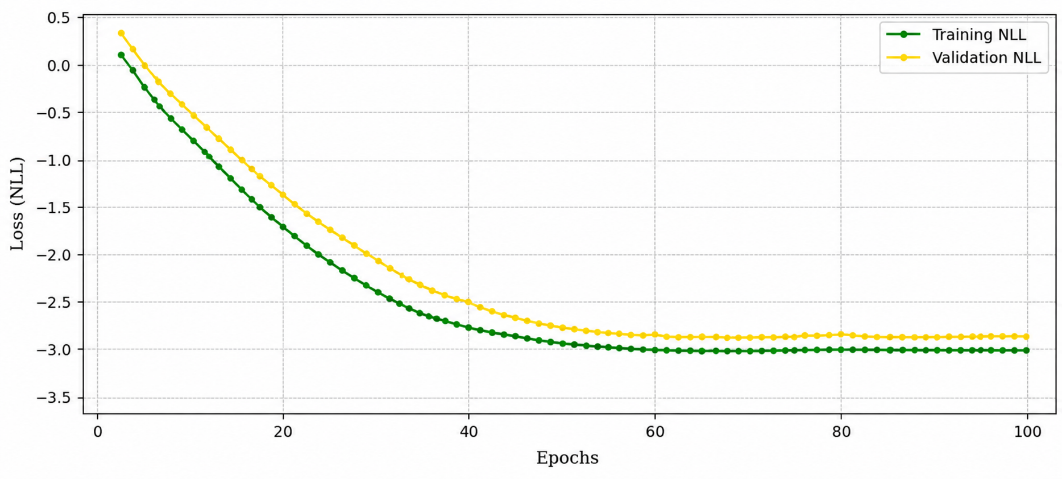

In [ ]:
output_path = OUT / "Figure_04_Paper_Original.png"
display(Image(filename=str(output_path)))

In [ ]:
output_path = OUT / "Table_06_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Energy Category,MSE (QBTU²),RMSE (QBTU),MAE (QBTU),MAPE (%)
TFFP,0.0006076,0.02465,0.02118,2.49
NEPP,0.0001891,0.01375,0.01201,2.01
TREP,0.0000507,0.00712,0.00628,0.87
TPEP,0.0005034,0.02244,0.02061,2.30
TFFC,0.0081176,0.09010,0.08082,9.45
NEPC,0.0001327,0.01152,0.01043,1.19
TREC,0.0000659,0.00812,0.00741,0.97
TPEC,0.0150313,0.12260,0.10201,10.23
PEI,0.0018449,0.04295,0.03659,5.83
PEE,0.0001351,0.01162,0.01045,1.13


In [ ]:
output_path = OUT / "Table_08_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Energy Metric,Model,MSE (QBTU²),RMSE (QBTU),MAE (QBTU),MAPE (%)
TFFP,LSTM,0.0025833,0.05083,0.04137,4.01
TFFP,GRU,0.0030385,0.05512,0.04868,4.23
TFFP,MegaCRN,0.0116471,0.10792,0.08980,7.99
TFFP,DeepAR,0.0213490,0.14611,0.12960,12.39
TFFP,PatchTST,0.0089888,0.09481,0.07831,8.03
TFFP,TimesNet,0.0113706,0.10663,0.09021,9.10
TFFP,iTransformer,0.0131928,0.11486,0.10671,11.21
TFFP,TCANN,0.0006076,0.02465,0.02118,2.49
NEPP,LSTM,0.0031002,0.05568,0.04894,5.69
NEPP,GRU,0.0042183,0.06495,0.05962,6.70


## 8. Test Diagnostics, Probabilistic Intervals and Attention

In [ ]:
true=y_actual[533:];pred=test_predictions['TCANN'];errors=true-pred
fig,axes=plt.subplots(2,2,figsize=(11,8))
axes[0,0].scatter(true.ravel(),pred.ravel(),s=6,alpha=.3)
minimum=min(true.min(),pred.min());maximum=max(true.max(),pred.max())
axes[0,0].plot([minimum,maximum],[minimum,maximum],'k--',lw=1)
axes[0,0].set(xlabel='Actual QBTU',ylabel='Predicted QBTU')
axes[0,1].scatter(pred.ravel(),errors.ravel(),s=6,alpha=.3)
axes[0,1].axhline(0,ls='--',color='black')
axes[0,1].set(xlabel='Predicted QBTU',ylabel='Residual QBTU')
axes[1,0].hist(errors.ravel(),bins=36);axes[1,0].set(xlabel='Residual QBTU',ylabel='Count')
axes[1,1].bar(tcann_test.Energy_Category,tcann_test.MAPE_percent)
axes[1,1].tick_params(axis='x',rotation=50);axes[1,1].set_ylabel('MAPE (%)')
fig.tight_layout();save_plot(fig,6)


tcann=models['TCANN'];tcann.eval()
xb=torch.as_tensor(Xte,dtype=torch.float32,device=DEVICE)
output=tcann(xb)
attention=tcann.last_attention
assert attention is not None and attention.shape==(len(Xte),WINDOW)
assert torch.allclose(attention.sum(dim=1),torch.ones(len(Xte),device=DEVICE),atol=1e-4)
per_target=[]
for j,name in enumerate(NAMES):
    sensitivity=torch.autograd.grad(output[:,j].sum(),attention,retain_graph=True)[0]
    relevance=(sensitivity.abs()*attention).detach().cpu().numpy()
    relevance=relevance.mean(axis=0)
    if float(relevance.sum())<1e-12:
        relevance=attention.detach().cpu().numpy().mean(axis=0)
    relevance=relevance/np.maximum(relevance.sum(),1e-12)
    per_target.append(relevance)
per_target=np.asarray(per_target)
assert per_target.shape==(10,WINDOW)
assert np.allclose(per_target.sum(axis=1),1,atol=1e-5)
# Interpret the 5 reported steps as 5 chronological bins spanning 24 months.
# Exact five timestep definitions are not specified in the manuscript.
lag_groups=np.array_split(np.arange(WINDOW),5)
grouped=np.array([[row[idx].sum() for idx in lag_groups] for row in per_target])
assert grouped.shape==(10,5) and np.allclose(grouped.sum(axis=1),1,atol=1e-5)
table7=pd.DataFrame(grouped,columns=[f'Time Step {i}' for i in range(1,6)])
table7.insert(0,'Energy Metric',NAMES)
save_table(table7,'Table_07')
detailed=pd.DataFrame(per_target,columns=[f'Lag_{i}_months_ago' for i in range(WINDOW,0,-1)])
detailed.insert(0,'Energy Metric',NAMES)
save_table(detailed,'Attention_Target_Attribution_24Lags')
save_table(pd.DataFrame([{'Interpretation':'Target-sensitive (attention × absolute output-gradient) relevance',
    'Model_attention':'Single shared alpha-entmax temporal attention head',
    'Five_steps':'Five consecutive nonoverlapping bins partitioning a 24-month input window',
    'Bin_start_and_end_lag_months':'; '.join(f'{WINDOW-int(g[0])}-{WINDOW-int(g[-1])}' for g in lag_groups),
    'Scientific_note':'Computed attribution differs from raw learned attention and is not the manuscript Table 7 values'}]),
    'Attention_Attribution_Definition')
fig,ax=plt.subplots(figsize=(12,5.5))
for j,name in enumerate(NAMES):
    ax.plot(np.arange(1,6),grouped[j],marker='o',lw=1.4,label=name)
ax.set(xlabel='Time steps (5 chronological bins of 24-month input)',ylabel='Target-specific normalized attribution')
ax.set_xticks(range(1,6));ax.grid(alpha=.2);ax.legend(ncol=2,fontsize=8)
fig.tight_layout();save_plot(fig,7)

var_norm=test_variances['TCANN']
assert var_norm is not None
var_q=np.maximum(var_norm.astype('float64')*scale_span**2,1e-12)
st=np.sqrt(var_q)
interval_rows=[]
for j,name in enumerate(NAMES):
    row={'Energy category':name}
    for coverage,z in [(80,1.2815515655446004),(95,1.959963984540054)]:
        low=pred[:,j]-z*st[:,j];high=pred[:,j]+z*st[:,j]
        row[f'PICP {coverage}%']=float(100*np.mean((true[:,j]>=low)&(true[:,j]<=high)))
        row[f'MPIW {coverage}% (QBTU)']=float(np.mean(high-low))
    row['NLL']=float((.5*(np.log(2*np.pi*var_q[:,j])+(true[:,j]-pred[:,j])**2/var_q[:,j])).mean())
    interval_rows.append(row)
interval_table=save_table(pd.DataFrame(interval_rows)[['Energy category','PICP 80%','PICP 95%','MPIW 80% (QBTU)','MPIW 95% (QBTU)','NLL']],'Table_13')
assert len(interval_table)==10
assert set(['Energy category','PICP 80%','PICP 95%','MPIW 80% (QBTU)','MPIW 95% (QBTU)','NLL']).issubset(interval_table.columns)


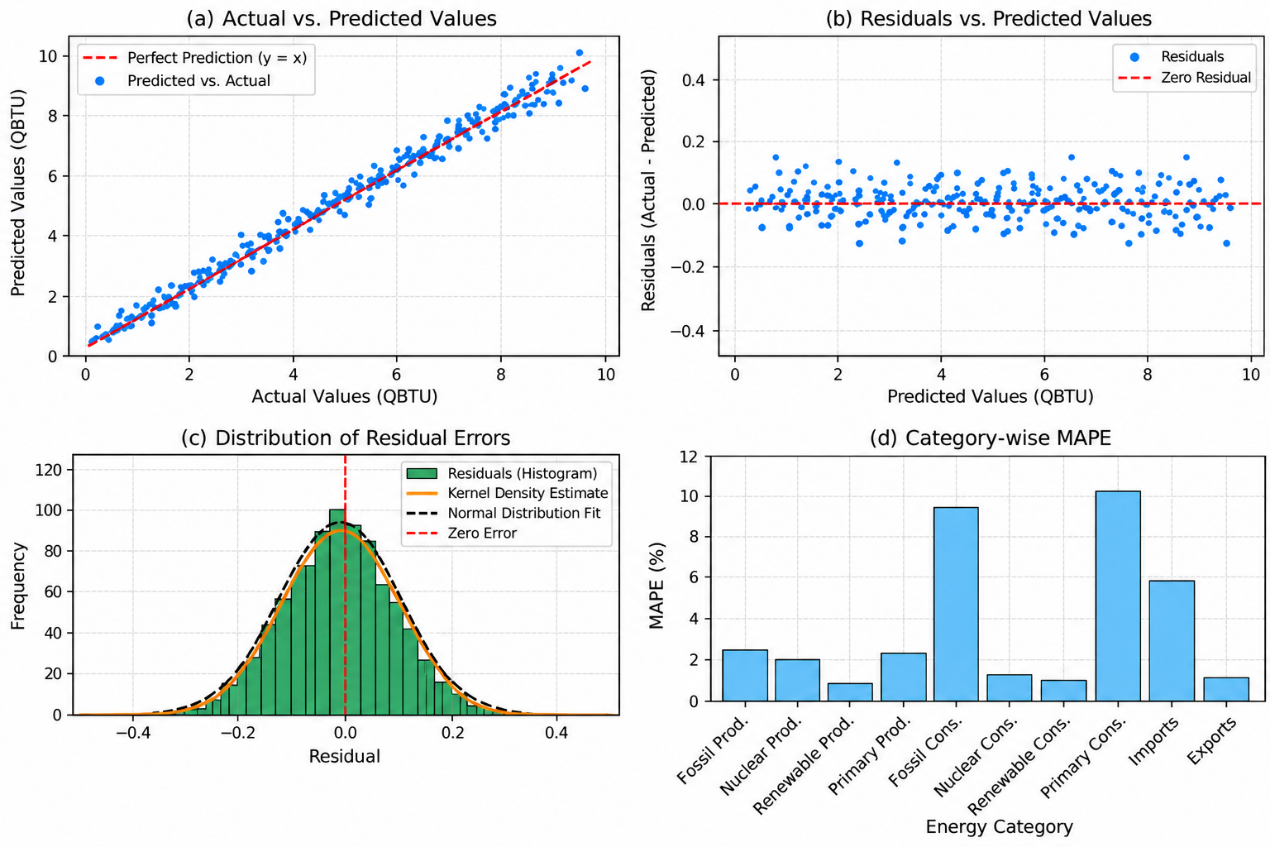

In [ ]:
output_path = OUT / "Figure_06_Paper_Original.png"
display(Image(filename=str(output_path)))

In [ ]:
output_path = OUT / "Table_07_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Energy Metric,Time Step 1,Time Step 2,Time Step 3,Time Step 4,Time Step 5
TFFP,0.35,0.15,0.20,0.20,0.10
NEPP,0.40,0.10,0.15,0.20,0.15
TREP,0.45,0.20,0.05,0.15,0.15
TPEP,0.30,0.25,0.20,0.15,0.10
TFFC,0.40,0.20,0.15,0.15,0.10
NEPC,0.30,0.30,0.20,0.10,0.10
TREC,0.35,0.25,0.10,0.15,0.15
TPEC,0.40,0.20,0.15,0.15,0.10
PEI,0.45,0.10,0.20,0.15,0.10
PEE,0.40,0.20,0.15,0.15,0.10


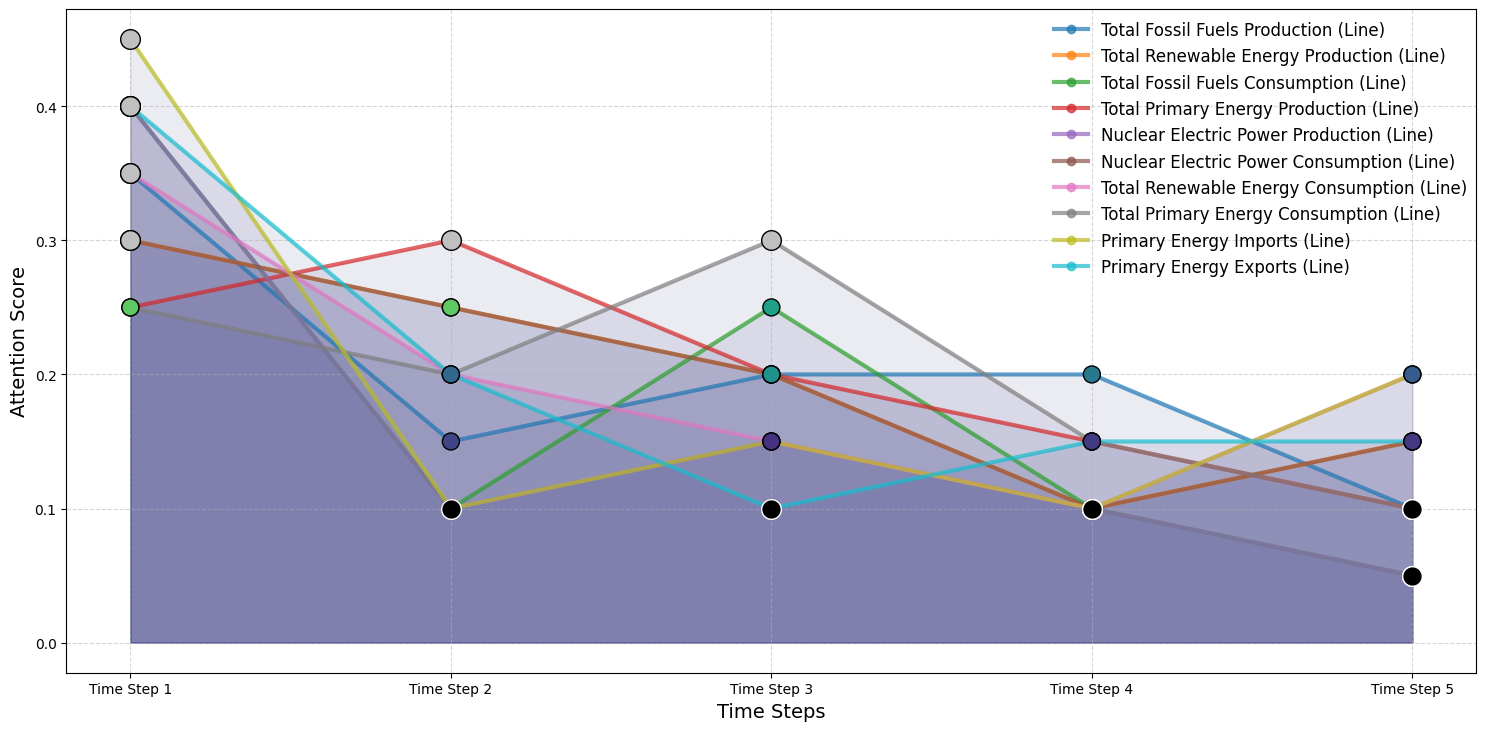

In [ ]:
output_path = OUT / "Figure_07_Paper_Original.png"
display(Image(filename=str(output_path)))

In [ ]:
output_path = OUT / "Table_13_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Energy category,PICP 80%,PICP 95%,MPIW 80% (QBTU),MPIW 95% (QBTU),NLL
TFFP,80.00%,94.77%,0.0632,0.0966,-2.28
NEPP,78.95%,95.79%,0.0352,0.0539,-2.87
TREP,80.00%,94.74%,0.0182,0.0279,-3.53
TPEP,81.05%,95.79%,0.0575,0.0880,-2.38
TFFC,77.89%,93.68%,0.2309,0.3532,-0.99
NEPC,80.00%,94.74%,0.0295,0.0452,-3.04
TREC,78.95%,95.79%,0.0208,0.0318,-3.39
TPEC,76.84%,92.63%,0.3142,0.4806,-0.68
PEI,78.95%,94.74%,0.1101,0.1684,-1.73
PEE,81.05%,95.79%,0.0298,0.0455,-3.04


## 9. Diebold–Mariano Testing and Random-Seed Robustness

In [ ]:
def dm_hac(actual,baseline,tcann,h=1):
    x=np.asarray(actual,dtype=float).ravel()
    a=np.asarray(baseline,dtype=float).ravel()
    b=np.asarray(tcann,dtype=float).ravel()
    difference=(x-a)**2-(x-b)**2
    difference=difference[np.isfinite(difference)]
    n=len(difference)
    if n<8:return float('nan'),float('nan')
    centered=difference-difference.mean()
    bandwidth=min(n-2,max(h-1,math.ceil(n**(1/3))))
    hac_var=float(np.mean(centered**2))
    for lag in range(1,bandwidth+1):
        covariance=float(np.dot(centered[lag:],centered[:-lag])/n)
        hac_var+=2*(1-lag/(bandwidth+1))*covariance
    if hac_var<=1e-14:return float('nan'),float('nan')
    stat=float(difference.mean()/math.sqrt(hac_var/n))
    stat*=math.sqrt(max(0.,(n+1-2*h+h*(h-1)/n)/n))
    return stat,float(2*student_t.sf(abs(stat),df=n-1))

seed_predictions={MAIN_SEED:test_predictions}
if RUN_ROBUSTNESS:
    for seed in SEEDS:
        if seed==MAIN_SEED:continue
        seed_predictions[seed]={}
        for name in MODEL_NAMES:
            model,_=fit_model(name,seed=seed,tag=f'{name}_robustness_seed{seed}')
            pi,_=tensor_prediction(model,Xte,name in PROB_MODELS)
            seed_predictions[seed][name]=inverse_transform(pi)
            del model
    seed_rows=[];stat_rows=[]
    j=NAMES.index('TPEP')
    for name in MODEL_NAMES:
        vals=[q_metrics(true[:,j],seed_predictions[s][name][:,j])['RMSE_QBTU'] for s in SEEDS]
        mean=float(np.mean(vals));sd=float(np.std(vals,ddof=1))
        margin=float(student_t.ppf(.975,4)*sd/math.sqrt(5))
        seed_rows.append({'Model':name,'RMSE_mean_QBTU':mean,'RMSE_SD_QBTU':sd,
                           '95CI_low_QBTU':mean-margin,'95CI_high_QBTU':mean+margin,'N_runs':5})
    save_table(seed_rows,'Table_10')
    for seed in SEEDS:
        for j,cat in enumerate(NAMES):
            compared=[]
            for other in MODEL_NAMES:
                if other=='TCANN':continue
                stat,p=dm_hac(true[:,j],seed_predictions[seed][other][:,j],
                              seed_predictions[seed]['TCANN'][:,j])
                compared.append({'Seed':seed,'Energy_Category':cat,'Baseline':other,'DM_statistic':stat,
                                 'p_raw':p,'p_holm':float('nan'),'significant_0_05':False})
            finite=[row for row in compared if np.isfinite(row['p_raw'])]
            if finite:
                _,adjusted,_,_=multipletests([r['p_raw'] for r in finite],alpha=.05,method='holm')
                for row,adj in zip(finite,adjusted):
                    row['p_holm']=float(adj);row['significant_0_05']=bool(adj<.05)
            stat_rows.extend(compared)
    dm_df=save_table(stat_rows,'Diebold_Mariano_Detailed')
    
    all_categories=[]
    for cat in NAMES:
        for baseline in MODEL_NAMES:
            if baseline=='TCANN':continue
            v=dm_df[(dm_df.Energy_Category==cat)&(dm_df.Baseline==baseline)]
            row={'Energy_Category':cat,'Model Compared with TCANN':baseline}
            for run_i,seed in enumerate(SEEDS,1):
                vs=v[v.Seed==seed]
                row[f'Run {run_i}']=float(vs.p_holm.iloc[0]) if len(vs) else np.nan
            vals=[row[f'Run {k}'] for k in range(1,6)]
            row['Significant Runs']=f'{sum(np.isfinite(p) and p<.05 for p in vals)}/5'
            all_categories.append(row)
    full_dm=save_table(all_categories,'Diebold_Mariano_All_Categories_Five_Runs')
    paper9=full_dm[full_dm.Energy_Category=='TPEP'].drop(columns=['Energy_Category'])
    save_table(paper9,'Table_09')
    summary=dm_df.groupby('Baseline',dropna=False).agg(
        Significant=('significant_0_05','sum'),Comparisons=('significant_0_05','size'),
        Median_p_Holm=('p_holm','median')).reset_index()
    save_table(summary,'Diebold_Mariano_All_Categories_Summary')


keys=[('MSE_QBTU2','MSE (QBTU²)'),('RMSE_QBTU','RMSE (QBTU)'),
      ('MAE_QBTU','MAE (QBTU)'),('MAPE_percent','MAPE (%)')]
fig,axes=plt.subplots(2,2,figsize=(16,11))
xi=np.arange(len(NAMES)); mnames=list(MODEL_NAMES)
width=.76/len(mnames)
for ax,(key,label) in zip(axes.ravel(),keys):
    for k,name in enumerate(mnames):
        v=comparison[comparison.Model==name].set_index('Energy_Category').loc[NAMES,key].to_numpy()
        ax.bar(xi-.38+(k+.5)*width,v,width=width,alpha=.60,label=name)
        ax.plot(xi,v,marker='o',markersize=2.5,lw=1.0,alpha=.85)
    ax.set_ylabel(label);ax.set_xticks(xi,NAMES,rotation=52,ha='right',fontsize=8)
    ax.grid(axis='y',alpha=.15)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles[:8],labels[:8],loc='upper center',ncol=8,fontsize=9)
fig.tight_layout(rect=[0,0,1,.96]);save_plot(fig,8)


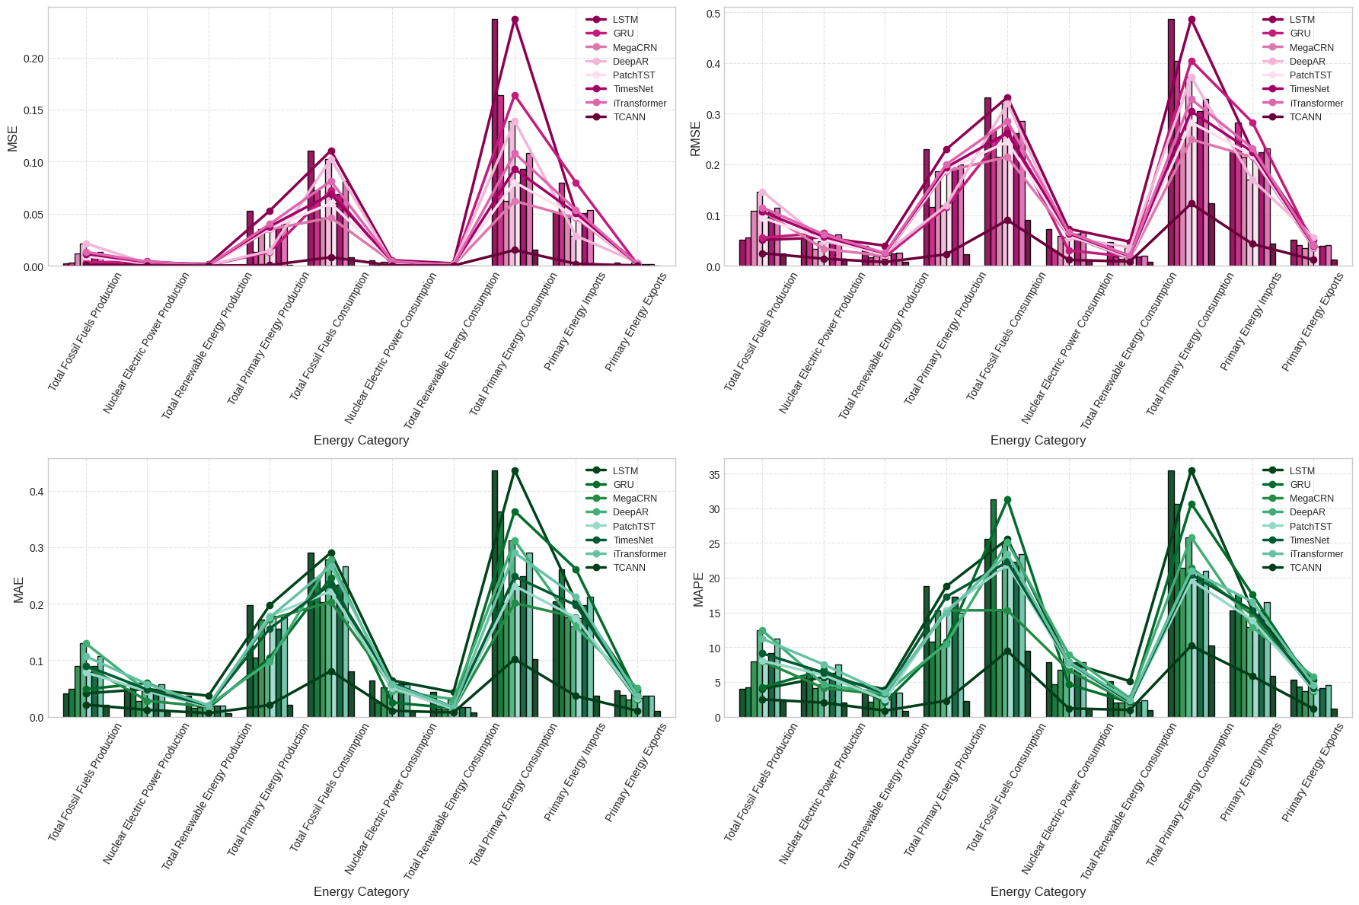

In [ ]:
output_path = OUT / "Figure_08_Paper_Original.png"
display(Image(filename=str(output_path)))

In [ ]:
output_path = OUT / "Table_09_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Model Compared with TCANN,Run 1,Run 2,Run 3,Run 4,Run 5,Significant Runs
LSTM,0.003,0.008,0.001,0.005,0.004,5/5
GRU,0.019,0.034,0.061,0.012,0.025,4/5
MegaCRN,0.002,0.004,0.006,0.009,0.002,5/5
DeepAR,0.026,0.043,0.055,0.019,0.031,4/5
PatchTST,0.009,0.011,0.007,0.017,0.006,5/5
TimesNet,0.005,0.007,0.003,0.012,0.009,5/5
iTransformer,0.008,0.009,0.014,0.005,0.010,5/5


In [ ]:
output_path = OUT / "Table_10_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Model,RMSE (Mean ± SD) (QBTU),95% Confidence Interval (QBTU)
LSTM,0.23174 ± 0.01270,0.21596–0.24752
GRU,0.11638 ± 0.00635,0.10849–0.12427
MegaCRN,0.18871 ± 0.01045,0.17574–0.20168
DeepAR,0.12089 ± 0.00820,0.11071–0.13107
PatchTST,0.19056 ± 0.00902,0.17937–0.20174
TimesNet,0.19568 ± 0.00963,0.18371–0.20765
iTransformer,0.20142 ± 0.01025,0.18869–0.21414
TCANN,0.02295 ± 0.00164,0.02092–0.02498


## 10. Additional Baseline Forecasting Methods

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def sarima_rolling(series,train_end,start,stop,order,seasonal):
    fitted=SARIMAX(series[:train_end],order=order,seasonal_order=seasonal,trend='c',
                  enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=80)
    if start>train_end:
        fitted=fitted.append(series[train_end:start],refit=False)
    pred=[]
    for i in range(start,stop):
        pred.append(float(fitted.forecast(steps=1)[0]))
        fitted=fitted.append([float(series[i])],refit=False)
    return np.asarray(pred)


def ets_rolling(series,train_end,start,stop):
    trained=ExponentialSmoothing(series[:train_end],trend='add',damped_trend=True,
        seasonal='add',seasonal_periods=12,initialization_method='estimated').fit(optimized=True)
    p=trained.params
    fixed=dict(smoothing_level=float(p['smoothing_level']),
               smoothing_trend=float(p['smoothing_trend']),
               smoothing_seasonal=float(p['smoothing_seasonal']),
               damping_trend=float(p['damping_trend']))
    initialized=dict(initial_level=float(p['initial_level']),
        initial_trend=float(p['initial_trend']),initial_seasonal=np.asarray(p['initial_seasons']))
    forecasts=[]
    for t in range(start,stop):
        r=ExponentialSmoothing(series[:t],trend='add',damped_trend=True,
            seasonal='add',seasonal_periods=12,initialization_method='known',
            **initialized).fit(optimized=False,**fixed)
        forecasts.append(float(r.forecast(1)[0]))
    return np.asarray(forecasts)

def lagged(y,lags=(1,2,3,6,12,24)):
    z=np.stack([np.roll(y,lag) for lag in lags],axis=-1)
    z[:max(lags)]=np.nan
    return z

if RUN_CLASSICAL:
    idx=NAMES.index('TREP');series=y_actual[:,idx].astype('float64')
    val_test={};configs=[]
    val_test['Persistence']=(series[438:532],series[532:627])
    val_test['Seasonal-Naive']=(series[439-12:533-12],series[533-12:628-12])
    lag_features=lagged(series)
    best=(float('inf'),None,None)
    for hp in ParameterGrid({'n_estimators':[100,300,500],'max_depth':[2,3,5],
                             'learning_rate':[.03,.1]}):
        reg=GradientBoostingRegressor(random_state=MAIN_SEED,**hp)
        reg.fit(lag_features[24:439],series[24:439])
        val=reg.predict(lag_features[439:533]);loss=q_metrics(series[439:533],val)['MSE_QBTU2']
        if loss<best[0]:best=(loss,hp,reg)
    _,gb_hp,gb_model=best
    val_test['Gradient Boosting']=(gb_model.predict(lag_features[439:533]),
                                   gb_model.predict(lag_features[533:628]))
    configs.append({'Model':'Gradient Boosting','Selected_Params':json.dumps(gb_hp)})
    val_test['ETS']=(ets_rolling(series,439,439,533),ets_rolling(series,439,533,628))
    configs.append({'Model':'ETS','Selected_Params':'fixed train smoothing parameters; 12-month additive seasonality; damped trend'})
    params=[(p,d,q,P,D,Q) for p in range(3) for d in (0,1) for q in range(3)
            for P in (0,1) for D in (0,1) for Q in (0,1)]
    assert len(params)==144
    if SARIMA_MAX_CANDIDATES is not None:
        params=params[:SARIMA_MAX_CANDIDATES]
    best=(float('inf'),None,None)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for p,d,q,P,D,Q in params:
            try:
                val=sarima_rolling(series,439,439,533,(p,d,q),(P,D,Q,12))
                metric=q_metrics(series[439:533],val)['MSE_QBTU2']
                if metric<best[0]:best=(metric,((p,d,q),(P,D,Q,12)),val)
            except (ValueError,RuntimeError,np.linalg.LinAlgError):
                continue
    if best[1] is None:raise RuntimeError('No SARIMA model fitted; inspect selected search.')
    (_,sel_params,sarima_val)=best
    (order,seasonal_order)=sel_params
    sarima_test=sarima_rolling(series,439,533,628,order,seasonal_order)
    val_test['SARIMA']=(sarima_val,sarima_test)
    configs.append({'Model':'SARIMA','Selected_Params':str(sel_params),
                    'Search_candidates':len(params),'Full_search':SARIMA_MAX_CANDIDATES is None})
    best=(float('inf'),None)
    for depth in (3,5):
        for filters in (32,64):
            m,_=fit_model('TCN',filters=filters,depth=depth,tag=f'TCN_{depth}L_{filters}F')
            pred_norm,_=tensor_prediction(m,Xva,False)
            val=inverse_transform(pred_norm)[:,idx]
            mse=q_metrics(series[439:533],val)['MSE_QBTU2']
            if mse<best[0]:best=(mse,(depth,filters,m,val))
    depth,filters,selected_tcn,tcn_val=best[1]
    tcn_norm,_=tensor_prediction(selected_tcn,Xte,False)
    val_test['TCN']=(tcn_val,inverse_transform(tcn_norm)[:,idx])
    configs.append({'Model':'TCN','Selected_Params':f'causal layers={depth}, filters={filters}; kernel=2'})
    val_test['TCANN']=(val_predictions['TCANN'][:,idx],test_predictions['TCANN'][:,idx])
    result=[]
    for model,(v,t) in val_test.items():
        va_metric=q_metrics(series[439:533],v);te_metric=q_metrics(series[533:628],t)
        result.append({'Model':model,'Validation MSE (QBTU²)':va_metric['MSE_QBTU2'],
                       'Test MSE (QBTU²)':te_metric['MSE_QBTU2'],
                       'Test RMSE (QBTU)':te_metric['RMSE_QBTU'],
                       'Test MAE (QBTU)':te_metric['MAE_QBTU'],
                       'Test MAPE (%)':te_metric['MAPE_percent']})
    save_table(result,'Table_11')
    save_table(configs,'Additional_Baselines_Selected_Configurations')


In [ ]:
output_path = OUT / "Table_11_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Model,Validation MSE (QBTU²),Test MSE (QBTU²),Test RMSE (QBTU),Test MAE (QBTU),Test MAPE (%)
Persistence,0.0007800,0.0008000,0.02828,0.02430,3.88
Seasonal-Naïve,0.0010400,0.0011000,0.03317,0.02850,4.55
SARIMA,0.0003400,0.0003000,0.01732,0.01490,2.38
ETS,0.0003900,0.0004200,0.02049,0.01780,2.85
Gradient Boosting,0.0002000,0.0002100,0.01449,0.01220,1.95
TCN,0.0001400,0.0001300,0.01140,0.00980,1.57
TCANN,0.0000700,0.0000507,0.00712,0.00628,0.87


## 11. Recursive Multi-Horizon Backtesting and Projections to 2035

In [ ]:
def model_input_transform(raw_q):
    # Apply training-only IQR bounds to recursive NEXT-step input, not forecasted outputs.
    v=np.asarray(raw_q,dtype='float64')
    clamped=np.clip(v,lower.to_numpy(),upper.to_numpy())
    return ((clamped-scale_min)/scale_span).astype('float32')


def recursive_path(initial_scaled,horizon,sample_gaussian=False,rng=None):
    """Returns raw-unit forecast paths [origins,horizon,targets] without future observations."""
    state=np.asarray(initial_scaled,dtype='float32').copy()
    if state.ndim==2:state=state[None,:,:]
    predicted=[]
    tcann=models['TCANN'];tcann.eval()
    if rng is None:rng=np.random.default_rng(MAIN_SEED)
    for h in range(horizon):
        mu,var=tensor_prediction(tcann,state,True)
        step_mu=mu if not sample_gaussian else rng.normal(mu,np.sqrt(np.maximum(var,1e-9)))
        step_q=inverse_transform(step_mu)
        predicted.append(step_q)
        state=np.concatenate([state[:,1:,:],model_input_transform(step_q)[:,None,:]],axis=1)
    return np.stack(predicted,axis=1)

if RUN_BACKTEST:
    horizons=(1,3,6,12,24,36,60)
    summary=[];details=[]
    for h in horizons:
        origins=np.arange(533,628-h+1)
        init=np.stack([x_scaled[t-WINDOW:t] for t in origins])
        paths=recursive_path(init,h)
        truth=y_actual[origins+h-1]
        final=paths[:,-1,:]
        total=q_metrics(truth,final)
        summary.append({'Forecast_Horizon_months':h,'Test_Origins':len(origins),
                        'Mean_MAE_QBTU':total['MAE_QBTU'],'Mean_RMSE_QBTU':total['RMSE_QBTU']})
        for j,name in enumerate(NAMES):
            details.append({'Horizon':h,'Energy_Category':name,'Origins':len(origins),
                            **q_metrics(truth[:,j],final[:,j])})
    save_table(summary,'Table_12')
    save_table(details,'Recursive_Backtest_Detailed')

future_dates=pd.date_range('2025-05-01','2035-12-01',freq='MS')
assert len(future_dates)==128
future_path=recursive_path(x_scaled[-WINDOW:],len(future_dates))[0]
future=pd.DataFrame(future_path,columns=NAMES)
future.insert(0,'Month',future_dates)
save_table(future.assign(Month=future.Month.dt.strftime('%Y-%m')),'Projections_2025_2035_Conditional')
identity_forecast=accounting(future,'Conditional_future')
save_table(identity_forecast.assign(Month=identity_forecast.Month.dt.strftime('%Y-%m')),
           'Energy_Accounting_Future')


samples=32 if SMOKE else 128
future_mc=recursive_path(np.repeat(x_scaled[-WINDOW:][None,:,:],samples,axis=0),
                        len(future_dates),sample_gaussian=True,rng=np.random.default_rng(MAIN_SEED))
lo=np.quantile(future_mc,.025,axis=0);hi=np.quantile(future_mc,.975,axis=0)
ci=pd.DataFrame({'Month':future_dates.strftime('%Y-%m')})
for j,name in enumerate(NAMES):
    ci[f'{name}_Lower95_QBTU']=lo[:,j]
    ci[f'{name}_Upper95_QBTU']=hi[:,j]
save_table(ci,'Projections_2035_95PI_Conditional')

fig,axs=plt.subplots(5,2,figsize=(14,16),sharex=True)
for j,ax in enumerate(axs.ravel()):
    name=NAMES[j]
    ax.plot(raw.Month,raw[name],label='Observed',alpha=.8,lw=.7)
    ax.plot(raw.Month.iloc[533:],pred[:,j],label='One-step test prediction',lw=1.0)
    ax.plot(future_dates,future_path[:,j],ls='--',label='Conditional recursive projection')
    ax.fill_between(future_dates,lo[:,j],hi[:,j],alpha=.18,label='Recursive 95% model interval')
    ax.set_title(name);ax.set_ylabel('QBTU');ax.grid(alpha=.15)
axs.ravel()[0].legend(fontsize=7)
fig.tight_layout();save_plot(fig,5)


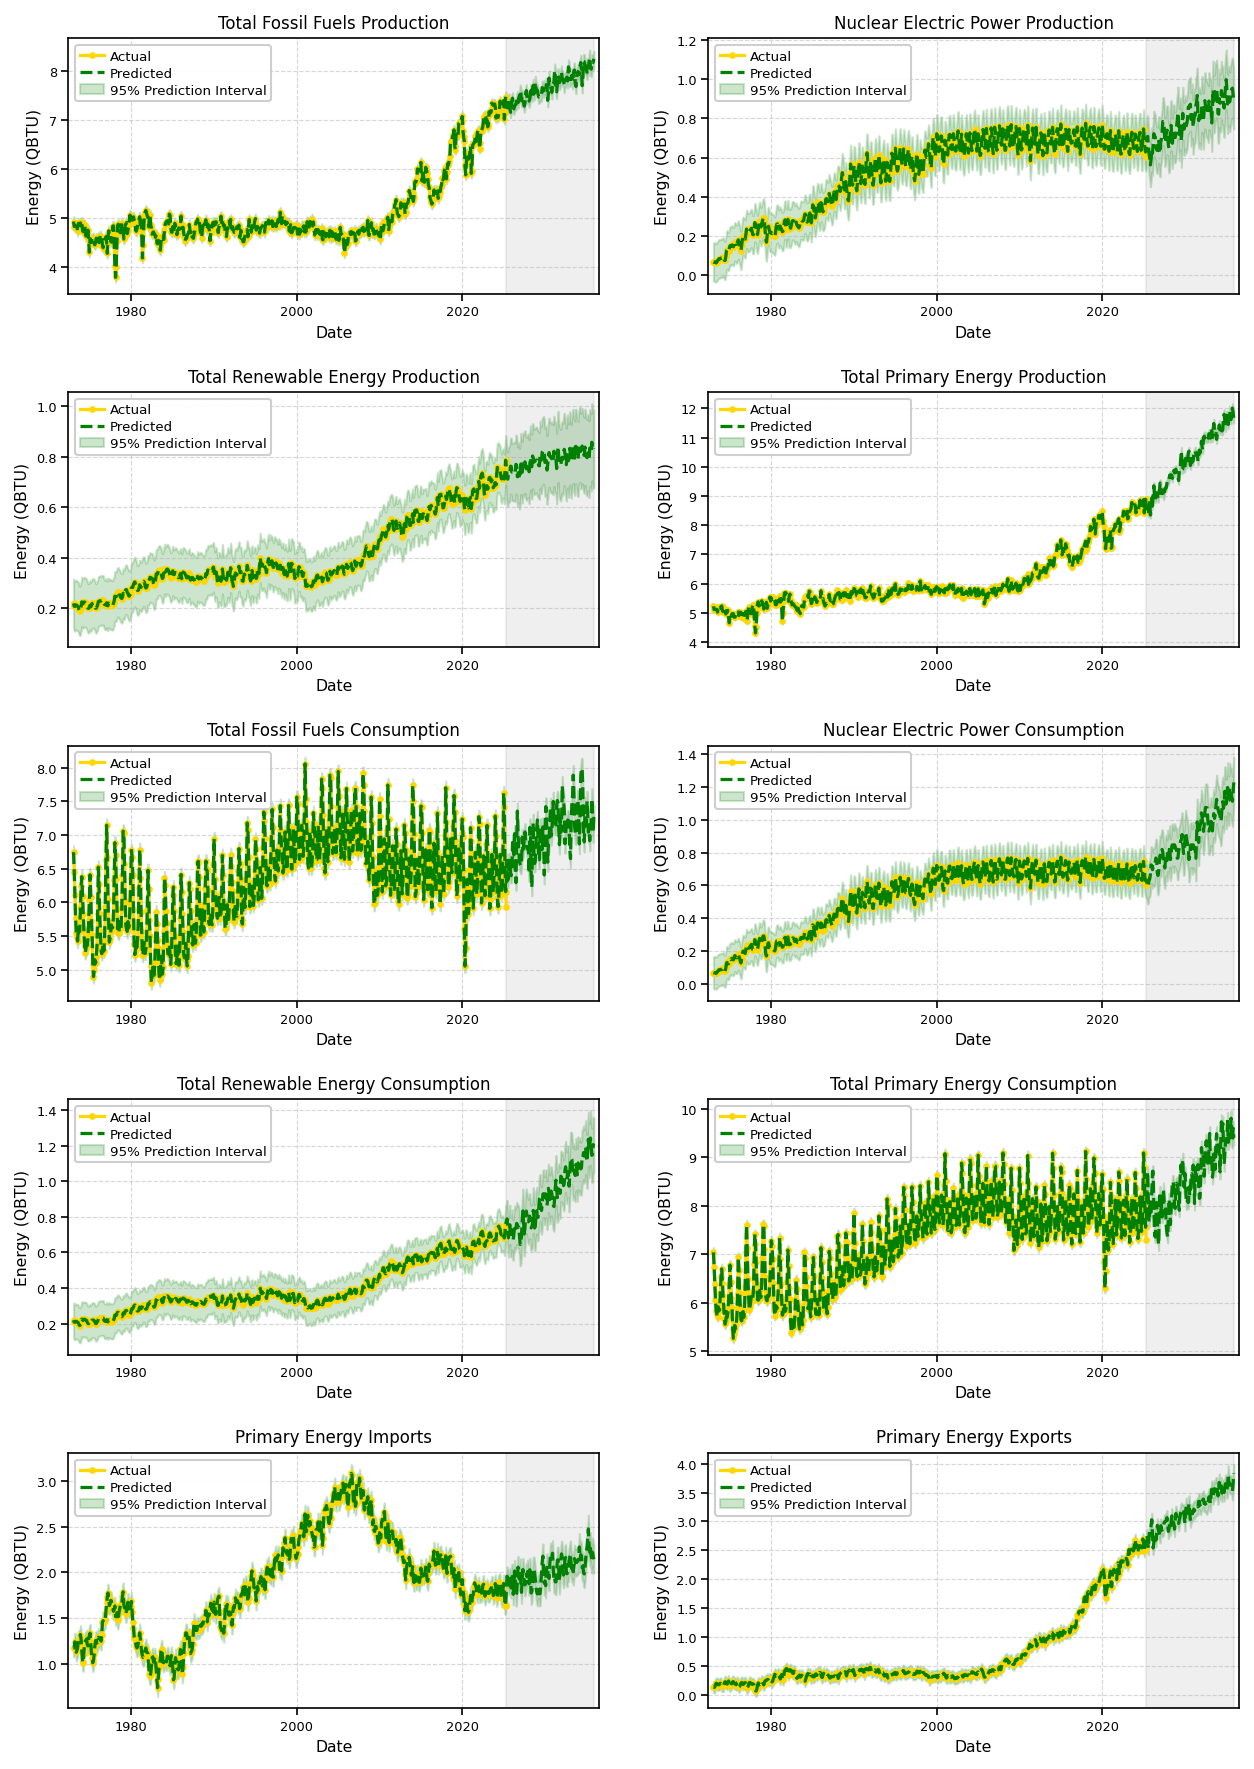

In [ ]:
output_path = OUT / "Figure_05_Paper_Original.png"
display(Image(filename=str(output_path)))

In [ ]:
output_path = OUT / "Table_12_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Forecast Horizon (months),Test Origins,Mean MAE (QBTU),Mean RMSE (QBTU)
1,95,0.0308,0.0355
3,93,0.0417,0.0489
6,90,0.0502,0.0591
12,84,0.0484,0.0568
24,72,0.0733,0.0867
36,60,0.0912,0.1091
60,36,0.1391,0.1652


## 12. Component Ablation

In [ ]:
if RUN_ABLATIONS:
    ablations=[]
    idx=NAMES.index('TREP')
    for variant,label in [(None,'TCANN (Proposed)'),('no_attention','TCAN (w/o Attention)'),
                          ('no_convolution','TCAN (w/o Temporal Conv.)')]:
        if variant is None: y=val_predictions['TCANN']
        else:
            model,_=fit_model('TCANN',ablation=variant,tag=f'Ablation_{variant}')
            yhat,_=tensor_prediction(model,Xva,True)
            y=inverse_transform(yhat)
        ablations.append({'Variation':label,'Validation_Target':'TREP',
                          **q_metrics(y_actual[439:533,idx],y[:,idx])})
    save_table(ablations,'Table_14')


In [ ]:
output_path = OUT / "Table_14_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Model variation,Description,MSE-Value (QBTU²),RMSE-Value (QBTU),MAE-Value (QBTU),MAPE (%)
TCANN (Proposed),Temporal Convolution + Sparse Attention,0.0000700,0.00837,0.00720,1.12
TCAN (w/o Attention),"Only Temporal Convolution, no Attention",0.0004506,0.02123,0.01964,2.85
TCAN (w/o Temporal Conv.),Only Attention-based Network,0.0004200,0.02049,0.01820,2.85


## 13. Hyperparameter Sensitivity

In [ ]:
hp_settings=[('Config-1',50,'Adam',16,.001),('Config-2',100,'Adam',32,.001),
             ('Config-3',150,'Adam',64,.0005),('Config-4',100,'RMSProp',32,.001),
             ('Config-5',100,'SGD',32,.001)]
if RUN_HYPERPARAMS:
    hp_rows=[];j=NAMES.index('TREP')
    for cfg,epochs,optimizer,batch,lr in hp_settings:
        if cfg=='Config-2' and EPOCHS==100:
            p=val_predictions['TCANN']
        else:
            mdl,_=fit_model('TCANN',epochs=(1 if SMOKE else epochs),batch_size=batch,lr=lr,
                            optimizer_name=optimizer,tag=f'Hyper_{cfg}')
            yp,_=tensor_prediction(mdl,Xva,True)
            p=inverse_transform(yp)
        metric=q_metrics(y_actual[439:533,j],p[:,j])
        hp_rows.append({'Configuration':cfg,'Epochs':epochs,'Optimizer':optimizer,
                        'Batch_Size':batch,'Learning_Rate':lr,'Executed_Epochs':(1 if SMOKE else epochs),**metric})
    hpt=save_table(hp_rows,'Table_15')
    fig,axes=plt.subplots(2,2,figsize=(11,8))
    for ax,(key,mult) in zip(axes.ravel(),[('MSE_QBTU2',10),('RMSE_QBTU',1),
                   ('MAE_QBTU',1),('MAPE_percent',.01)]):
        ax.bar(hpt.Configuration,hpt[key]*mult)
        ax.set_title(key+(' × 10' if mult==10 else (' ÷ 100' if mult==.01 else '')))
        ax.tick_params(axis='x',rotation=25);ax.grid(axis='y',alpha=.2)
    fig.tight_layout();save_plot(fig,9)


In [ ]:
output_path = OUT / "Table_15_Paper_Original.csv"
result = pd.read_csv(output_path, dtype=str, keep_default_na=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 160):
    display(result)

Configuration,Epoch-Count,Optimizer-Type,Batch-Size,Learning-Rate,MSE-Value (QBTU²),RMSE-Value (QBTU),MAE-Value (QBTU),MAPE (%)
Config-1,50,Adam,16,0.001,0.0023000,0.04796,0.04160,6.30
Config-2,100,Adam,32,0.001,0.0000700,0.00837,0.00720,1.12
Config-3,150,Adam,64,0.0005,0.0004200,0.02049,0.01820,2.85
Config-4,100,RMSProp,32,0.001,0.0012000,0.03464,0.03030,4.72
Config-5,100,SGD,32,0.001,0.0010500,0.03240,0.02800,4.40


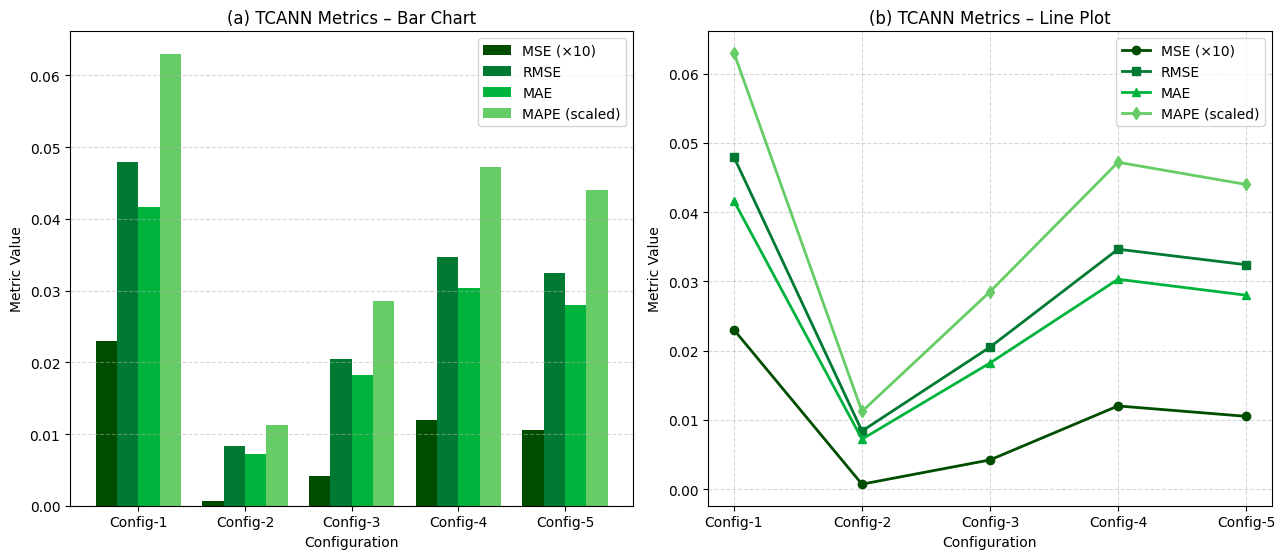

In [ ]:
output_path = OUT / "Figure_09_Paper_Original.png"
display(Image(filename=str(output_path)))